# Segmentation Analysis: Do Device, Channel, and Time Change Conversion?
Business question: does the tunnel behave differently across device, traffic sources, or months, and are the differences statistically meaningful?
Data: Synthetic Web Analytics Funnel Events (GenerateRealData, CC BY 4.0).

In [1]:
#IMPORT DAN KONEKSI
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

con = sqlite3.connect('../data/web_funnel_events.sqlite')

In [2]:
#SATU BARU PER SESI
sessions = pd.read_sql("SELECT * FROM sessions", con, parse_dates=["started_at"])

stage_flags = pd.read_sql("""
SELECT session_id,
  MAX(event_name='view_product')   AS viewed,
  MAX(event_name='add_to_cart')    AS carted,
  MAX(event_name='begin_checkout') AS checkout,
  MAX(event_name='purchase')       AS purchased
FROM events
GROUP BY session_id
""", con)

df = sessions.merge(stage_flags, on="session_id", how="left")
stage_cols = ["viewed", "carted", "checkout", "purchased"]
df[stage_cols] = df[stage_cols].fillna(0).astype(int)
df["month"] = df["started_at"].dt.to_period("M").astype(str)

print(df.shape, "overall conversion:", round(df["purchased"].mean() * 100, 2), "%")

(84000, 13) overall conversion: 9.06 %


In [3]:
#FUNGSI FUNNEL PER SEGMEN
def segment_funnel(df, col):
    g = df.groupby(col).agg(
        sessions=("session_id", "count"),
        viewed=("viewed", "sum"),
        carted=("carted", "sum"),
        checkout=("checkout", "sum"),
        purchased=("purchased", "sum"))
    out = pd.DataFrame({
        "sessions": g["sessions"],
        "view_rate_%": g["viewed"] / g["sessions"] * 100,
        "cart_rate_%": g["carted"] / g["viewed"] * 100,
        "checkout_rate_%": g["checkout"] / g["carted"] * 100,
        "purchase_rate_%": g["purchased"] / g["checkout"] * 100,
        "overall_conversion_%": g["purchased"] / g["sessions"] * 100
    }).round(2)
    return out.sort_values("overall_conversion_%", ascending=False)

display(segment_funnel(df, "device"))
display(segment_funnel(df, "referrer"))
display(segment_funnel(df, "month"))

,sessions,view_rate_%,cart_rate_%,checkout_rate_%,purchase_rate_%,overall_conversion_%
device,,,,,,
mobile,48859,67.17,40.19,56.56,59.93,9.15
desktop,28528,67.74,39.97,56.85,58.01,8.93
tablet,6613,67.10,39.44,56.69,59.48,8.92


,sessions,view_rate_%,cart_rate_%,checkout_rate_%,purchase_rate_%,overall_conversion_%
referrer,,,,,,
partner site,4252,66.86,40.10,58.68,60.54,9.52
instagram,9305,67.53,40.36,56.55,60.32,9.30
facebook,7546,67.86,41.48,56.07,58.61,9.25
bing,4091,67.25,40.86,55.34,60.61,9.22
direct,19967,67.24,39.23,56.80,60.11,9.00
google,32182,67.34,40.34,56.90,58.05,8.97
newsletter,6657,67.34,38.63,55.54,60.08,8.68


,sessions,view_rate_%,cart_rate_%,checkout_rate_%,purchase_rate_%,overall_conversion_%
month,,,,,,
2026-09,26697,67.49,40.44,57.16,59.90,9.35
2026-07,28628,67.19,40.03,57.04,58.45,8.97
2026-08,28675,67.40,39.73,55.83,59.41,8.88


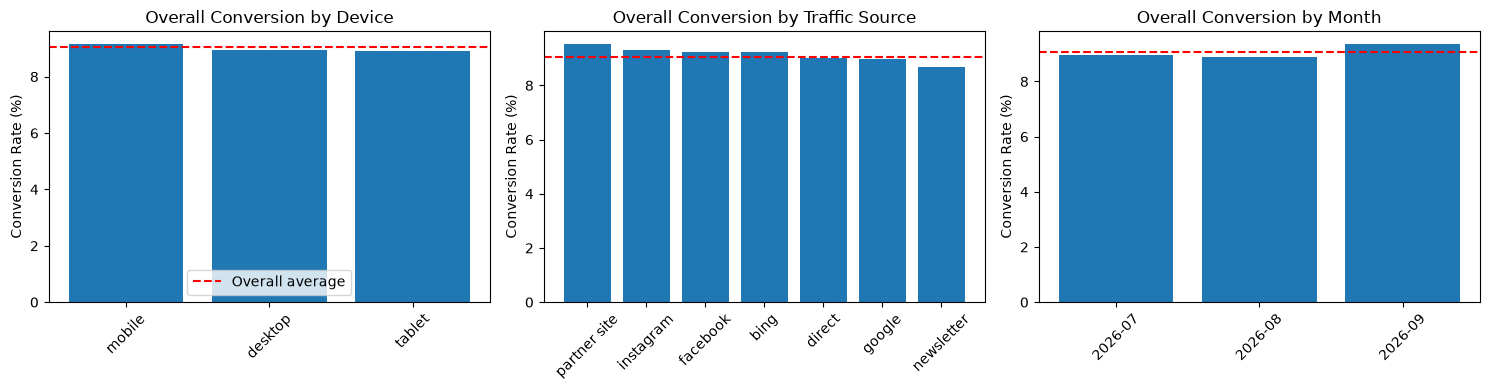

In [4]:
#GRAFIK
overall = df["purchased"].mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(axes, ["device", "referrer", "month"],
                          ["Device", "Traffic Source", "Month"]):
    t = segment_funnel(df, col)
    if col == "month":
        t = t.sort_index()
    ax.bar(t.index, t["overall_conversion_%"])
    ax.axhline(overall, color="red", linestyle="--", label="Overall average")
    ax.set_title(f"Overall Conversion by {title}")
    ax.set_ylabel("Conversion Rate (%)")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend()
plt.tight_layout()
plt.show()

In [5]:
#UJI CHI-SQUARE PER SEGMEN
def chi2_test(df, col):
    ct = pd.crosstab(df[col], df["purchased"])
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return pd.Series({"chi2": round(chi2, 2), "p_value": round(p, 4),
                      "dof": dof, "cramers_v": round(cramers_v, 4)})

results = pd.DataFrame({c: chi2_test(df, c) for c in
                        ["device", "referrer", "month", "browser", "landing_page"]}).T
results

,chi2,p_value,dof,cramers_v
device,1.21,0.5452,2.0,0.0038
referrer,3.71,0.7160,6.0,0.0066
month,4.04,0.1323,2.0,0.0069
browser,7.86,0.0968,4.0,0.0097
landing_page,6.67,0.4645,7.0,0.0089


In [6]:
#CONTOH PERBANDINGAN DUA SEGMEN
best, worst = "partner site", "newsletter"
a = df.loc[df["referrer"] == best, "purchased"]
b = df.loc[df["referrer"] == worst, "purchased"]

z, p = proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])
lo, hi = confint_proportions_2indep(a.sum(), len(a), b.sum(), len(b), compare="diff")

print(f"{best}: {a.mean():.2%} | {worst}: {b.mean():.2%}")
print(f"p-value: {p:.3f} | 95% CI of difference: [{lo*100:.2f}, {hi*100:.2f}] pp")

partner site: 9.52% | newsletter: 8.68%
p-value: 0.134 | 95% CI of difference: [-0.26, 1.97] pp


In [7]:
#WAKTU PER TAHAP
step_time = pd.read_sql("""
SELECT event_name, secs_on_step FROM events WHERE event_name != 'session_start'
""", con)
display(step_time.groupby("event_name")["secs_on_step"].agg(["count", "median", "mean"]).round(1))
display(df.groupby("purchased")["duration_s"].median())

,count,median,mean
event_name,,,
add_to_cart,23934,39.0,61.9
begin_checkout,12844,38.0,61.2
exit,75098,39.0,61.5
purchase,7609,39.0,61.3
search,20907,38.0,61.5
view_product,79917,39.0,61.9


purchased
0    186.0
1    323.0
Name: duration_s, dtype: float64

## KEY FINDINGS
- Conversion is nearly identical across devices (8.92-9.15%), traffic sources
  (8.68-9.52%), and months (8.88-9.35%).
- Chi-square tests show no statistically significant difference for any segment
  (all p > 0.05, Cramér's V < 0.01).
- Time spent per step is flat (~39s median), so no single step is "slow".
- Implication: the drop-off between Viewed Product and Added to Cart is a
  site-wide issue, not specific to one segment. Fixing it requires a
  site-wide change, which should be validated with an A/B test.